# Experiment 04 — PdO on Si-based stacks: design of experiments for Al₂O₃-on-Si and TiO₂-on-Si

After the 2026-09-15 NU/ND meeting (`raw_data_received/pdo/08_27_26/meeting_notes.txt`) the campaign moves to two stacks on a
Si base, ALD Al₂O₃ on SiO₂/Si and TiO₂ on SiO₂/Si, with a batch of 23 conditions × 3 replicates per stack. This notebook
(1) states the design space next to the sapphire design, (2) compares the candidate generators on the campaign's four
space-filling metrics under these bounds, (3) generates the design with the best of them, (4) shows coverage and where the
sapphire data sit, and (5) exports the run sheets. Every bound and the generator are named constants; change and re-run.

In [1]:
import os, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from scipy.stats import qmc
from scipy.spatial.distance import pdist, cdist
warnings.filterwarnings('ignore')

REPO_ROOT = '/data/zhq7531/IDEAL/DMREF/repository_dmref'
os.chdir(REPO_ROOT)
SAPPHIRE_RUNS = 'Processed_data_inputs/pdo/experiment02/Raw_update_05_22_2026.txt'     # factors + Hall of the 69 sapphire films

BLUE, ORANGE, AQUA, MUTED, INK, INK2 = '#2a78d6', '#eb6834', '#1baf7a', '#898781', '#0b0b0b', '#52514e'
FAIL = '#d03b3b'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
                     'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'text.color': INK, 'axes.labelcolor': INK2, 'xtick.color': INK2,
                     'ytick.color': INK2, 'legend.frameon': False, 'font.family': 'sans-serif'})
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)

# ---- saving: nothing is written unless SAVE_OUTPUTS is True -------------------------------------------------
SAVE_OUTPUTS = False                                    # True -> write the items below into OUT_DIR
OUT_DIR = 'output/pdo/experiment04_si_stacks_doe'
OUT_FILES = {                                           # file name per item; set an entry to None to skip it
    'design_space_table':       'design_space.xlsx',
    'two_stack_table':          'two_stack_comparison.xlsx',
    'two_stack_fig':            'two_stack_comparison.png',
    'future_iterations_table':  'future_iterations.xlsx',
    'future_iterations_fig':    'future_iterations.png',
    'future_iterations_known_table': 'future_iterations_from_known_sapphire.xlsx',
    'future_iterations_known_fig':   'future_iterations_from_known_sapphire.png',
    'sapphire_fixed_table':     'sapphire_fixed_check.xlsx',
    'sapphire_fixed_fig':       'sapphire_fixed_check.png',
    'pool_check_table':         'pool_selection_check.xlsx',
    'pool_check_fig':           'pool_selection_check.png',
    'correlation_fig':          'design_correlation_matrix.png',
    'correlation_per_stack_fig': 'design_correlation_matrix_per_stack.png',
    'distributions_fig':        'design_factor_distributions.png',
    'temperature_plane_fig':    'temperature_plane_vs_sapphire.png',
    'run_sheet':                'PdO_SiStacks_{method}_design.xlsx',   # {method} -> oLHS / Sobol / LHS
}

def save(key, obj):
    # Write obj (a DataFrame -> .xlsx, a matplotlib Figure -> .png) to OUT_DIR/OUT_FILES[key]; no-op unless SAVE_OUTPUTS.
    name = OUT_FILES.get(key)
    if not SAVE_OUTPUTS or name is None:
        return
    os.makedirs(OUT_DIR, exist_ok=True)
    path = os.path.join(OUT_DIR, name.format(method=globals().get('METHOD_TAG', '')))
    if hasattr(obj, 'savefig'):
        obj.savefig(path, dpi=170, bbox_inches='tight')
    else:
        obj.to_excel(path, index=False)
    print('saved', path)
print('SAVE_OUTPUTS =', SAVE_OUTPUTS, '| nothing is written to disk unless set to True')

SAVE_OUTPUTS = False | nothing is written to disk unless set to True


## 1. Design space

Same ten factors, names and units as the sapphire Sobol design (`experiment02_pdo_analysis.ipynb`), so the 41 sapphire
rows can live in the same model once the base-substrate question is settled. Bounds change only where the data justify
it (anneal cap, minimum power); deposition temperature, oxidation temperature, oxidation time and thickness keep
the sapphire ranges because the best sapphire conditions sit at high oxidation temperature and the meeting did not
decide a time cap. The one item still marked **CONFIRM** is the oxidation-pressure levels.

In [2]:
N_CONDITIONS   = 23        # chamber capacity per run (meeting 2026-09-15)
NUM_REPLICATES = 3
PAIRED_DESIGNS = False     # False: 46 distinct recipes - the TiO2 batch is placed in the gaps of the Al2O3 batch (no recipe repeated across stacks)
                           # True:  the same 23 recipes on both stacks (matched comparison, but 23 distinct points only)
STACKS = {'AlSi': 'ALD Al2O3 on SiO2/Si', 'TiSi': 'TiO2 on SiO2/Si'}   # prefix -> description

DEP_TEMP_LEVELS = [25.0, 425.0]   # decided: both sapphire levels kept (ND undecided on dropping 25 °C; 25 °C films had the higher carrier conc.)
OX_TEMP_MAX     = 700.0           # decided: sapphire range kept - the best low-carrier condition (#14) was oxidised at 695 °C. ND: Si runs hotter, expect failures near the top
OX_TIME_MAX     = 120.0           # decided: full 0-120 min range kept as in the meeting (ND's <= 5 min idea was a thought, not a decision)
OX_PRESS_LEVELS = [0.02, 1.0]     # CONFIRM: sapphire levels (1 atm gave only low mobility); HfO2 design used [0.01, 0.02]
VAC_ANN_MAX     = 300.0           # decided: on HfO2/Si every condition annealed at >= 325 °C failed, <= 250 °C survived (5 conditions); on sapphire failures > 513 °C; PdO decomposes in vacuum
THICK_MIN, THICK_MAX = 1.0, 10.0  # decided: sapphire range kept (1.7 and 1.9 nm films were measurable on sapphire; ND to say if there is a practical minimum)

CONFIG = {
    'Dep Power (W)':      {'min': 2.0,   'max': 40.0,        'step': 1.0},
    'O2 Flow (sccm)':     {'min': 0.3,   'max': 20.0,        'step': 0.1},
    'Dep Press (mTorr)':  {'min': 2.0,   'max': 10.0,        'step': 0.1},
    'Dep Temp (°C)':      DEP_TEMP_LEVELS,
    'Ox Temp (°C)':       {'min': 200.0, 'max': OX_TEMP_MAX, 'step': 5.0},
    'Ox Press (atm)':     OX_PRESS_LEVELS,
    'Ox Time (min)':      {'min': 0.0,   'max': OX_TIME_MAX, 'step': 0.1},
    'Vac Ann Temp (°C)':  {'min': 25.0,  'max': VAC_ANN_MAX, 'step': 5.0},
    'Vac Ann Time (min)': {'min': 0.0,   'max': 120.0,       'step': 0.1},
    'Dep Thickness (nm)': {'min': THICK_MIN, 'max': THICK_MAX, 'step': 0.1},
}
FACTORS = list(CONFIG)
SAPPHIRE = {'Dep Power (W)': (0, 40), 'O2 Flow (sccm)': (0.3, 20), 'Dep Press (mTorr)': (2, 10), 'Dep Temp (°C)': '25 / 425',
            'Ox Temp (°C)': (200, 800), 'Ox Press (atm)': '0.02 / 1', 'Ox Time (min)': (0, 120), 'Vac Ann Temp (°C)': (25, 800),
            'Vac Ann Time (min)': (0, 120), 'Dep Thickness (nm)': (1, 10)}
REASON = {
    'Dep Power (W)':      ('0 W is not a deposition; 2 W as in the HfO2 design', 'decided'),
    'O2 Flow (sccm)':     ('unchanged', '—'),
    'Dep Press (mTorr)':  ('unchanged', '—'),
    'Dep Temp (°C)':      ('both sapphire levels kept; ND undecided on dropping 25 °C, which gave higher carrier concentration', 'decided'),
    'Ox Temp (°C)':       ('sapphire range kept: the best low-carrier condition #14 was oxidised at 695 °C. ND reports films on Si dying near a 500 °C set point, so failures near the top of the range are possible', 'decided (risk accepted)'),
    'Ox Press (atm)':     ('sapphire levels kept so the sapphire data stay inside the space; note 1 atm gave < 3 cm²/V·s everywhere', 'CONFIRM'),
    'Ox Time (min)':      ('full range kept per the meeting; ND may test a short-time cap separately', 'decided'),
    'Vac Ann Temp (°C)':  ('HfO2/Si trial: failures at 325, 410, 440 °C, successes at 75, 250 °C (5 conditions, may be partly HfO2-specific); sapphire failures > 513 °C; PdO decomposes in vacuum', 'decided'),
    'Vac Ann Time (min)': ('unchanged', '—'),
    'Dep Thickness (nm)': ('unchanged: the one thin sapphire failure (#13, 1.5 nm) is explained by its 546 °C anneal; 1.7 and 1.9 nm films were measurable', '—'),
}
rows = []
for f, s in CONFIG.items():
    new = ' / '.join(f'{v:g}' for v in s) if isinstance(s, list) else f"{s['min']:g} – {s['max']:g} (step {s['step']:g})"
    old = SAPPHIRE[f] if isinstance(SAPPHIRE[f], str) else f'{SAPPHIRE[f][0]:g} – {SAPPHIRE[f][1]:g}'
    rows.append(dict(factor=f, sapphire_design=old, new_design=new, reason=REASON[f][0], status=REASON[f][1]))
bounds_tbl = pd.DataFrame(rows).set_index('factor')
bounds_tbl

,sapphire_design,new_design,reason,status
factor,,,,
Dep Power (W),0 – 40,2 – 40 (step 1),0 W is not a deposition; 2 W as in the HfO2 de...,decided
O2 Flow (sccm),0.3 – 20,0.3 – 20 (step 0.1),unchanged,—
Dep Press (mTorr),2 – 10,2 – 10 (step 0.1),unchanged,—
Dep Temp (°C),25 / 425,25 / 425,both sapphire levels kept; ND undecided on dro...,decided
Ox Temp (°C),200 – 800,200 – 700 (step 5),sapphire range kept: the best low-carrier cond...,decided (risk accepted)
Ox Press (atm),0.02 / 1,0.02 / 1,sapphire levels kept so the sapphire data stay...,CONFIRM
Ox Time (min),0 – 120,0 – 120 (step 0.1),full range kept per the meeting; ND may test a...,decided
Vac Ann Temp (°C),25 – 800,25 – 300 (step 5),"HfO2/Si trial: failures at 325, 410, 440 °C, s...",decided
Vac Ann Time (min),0 – 120,0 – 120 (step 0.1),unchanged,—


In [3]:
# the design space in the compact form used for the sapphire batch: factor / type / min / max / resolution
rows = []
for f, s in CONFIG.items():
    if isinstance(s, list):
        rows.append(dict(factor=f, type='two-level', min=min(s), max=max(s), resolution='levels ' + ' / '.join(f'{v:g}' for v in s)))
    else:
        rows.append(dict(factor=f, type='continuous', min=s['min'], max=s['max'], resolution=f"{s['step']:g}"))
design_space = pd.DataFrame(rows).set_index('factor')
save('design_space_table', design_space.reset_index())
design_space

,type,min,max,resolution
factor,,,,
Dep Power (W),continuous,2.00,40.0,1
O2 Flow (sccm),continuous,0.30,20.0,0.1
Dep Press (mTorr),continuous,2.00,10.0,0.1
Dep Temp (°C),two-level,25.00,425.0,levels 25 / 425
Ox Temp (°C),continuous,200.00,700.0,5
Ox Press (atm),two-level,0.02,1.0,levels 0.02 / 1
Ox Time (min),continuous,0.00,120.0,0.1
Vac Ann Temp (°C),continuous,25.00,300.0,5
Vac Ann Time (min),continuous,0.00,120.0,0.1


In [4]:
# unit cube <-> physical (snapped to the tool grid); a single-level factor is pinned and takes no dimension
def map_parameter(u, s):
    if isinstance(s, list):
        return s[min(int(u * len(s)), len(s) - 1)]
    val = s['min'] + u * (s['max'] - s['min'])
    return float(round(round(val / s['step']) * s['step'], 4))

VARYING = [f for f in FACTORS if not (isinstance(CONFIG[f], list) and len(CONFIG[f]) == 1)]
PINNED = {f: CONFIG[f][0] for f in FACTORS if f not in VARYING}
d = len(VARYING)

def to_physical(U):
    df = pd.DataFrame([[map_parameter(U[r, i], CONFIG[VARYING[i]]) for i in range(d)] for r in range(len(U))], columns=VARYING)
    for f, v in PINNED.items():
        df[f] = v
    return df[FACTORS]

def to_unit(df):
    M = np.zeros((len(df), d))
    for i, f in enumerate(VARYING):
        s = CONFIG[f]
        M[:, i] = df[f].map({v: j / (len(s) - 1) for j, v in enumerate(s)}).to_numpy() if isinstance(s, list) \
                  else (df[f].to_numpy(float) - s['min']) / (s['max'] - s['min'])
    return np.clip(M, 0, 1)

def _round_norm(U):                      # unit cube -> physical (snapped) -> unit cube  ("as fabricated")
    return to_unit(to_physical(U))

print(f'{d} varying factors: {VARYING}; pinned: {PINNED or "none"}')

10 varying factors: ['Dep Power (W)', 'O2 Flow (sccm)', 'Dep Press (mTorr)', 'Dep Temp (°C)', 'Ox Temp (°C)', 'Ox Press (atm)', 'Ox Time (min)', 'Vac Ann Temp (°C)', 'Vac Ann Time (min)', 'Dep Thickness (nm)']; pinned: none


## 2. Which generator? Scored on the task we actually have

The task is not one batch. It is **two stacks × 23 recipes now, with no recipe repeated across stacks, further rounds of
23 per stack later, and the sapphire recipes inside the new box, which may count as already-known locations**. Every candidate generator is
scored on that task, as fabricated (points snapped to the tool grid and mapped back to the unit cube), with the four
metrics the campaign has used since the HfO₂ designs (`experiment03_hfo2_doe_design.ipynb`,
`experiment03_hfo2_batch1_analysis_doe_n_caped_300.ipynb`):

* **Centered L2 discrepancy** ↓ — global uniformity: does every region and every factor projection get its share of runs?
  The primary space-filling metric.
* **Min pairwise distance** ↑ — maximin: no two runs nearly duplicated.
* **Max |factor correlation|** ↓ — factor independence; |r| < 0.3 is the confounding guard used throughout the campaign.
* **Fill distance** ↓ — the largest hole: the maximum distance from any of 100 000 probe points to its nearest run, where
  GP predictions will be weakest.

Candidates, all built on `scipy.stats.qmc`:

* **Sobol** — `qmc.Sobol(d, scramble=True, seed)`: scrambled Sobol sequence (the word used in the meeting); batches are
  consecutive stretches of one sequence.
* **Plain LHS** — `qmc.LatinHypercube(d, seed)`: a random Latin hypercube per batch, uniform 1-D marginals, no joint
  optimisation.
* **Optimised LHS** — `qmc.LatinHypercube(d, optimization='random-cd', seed)`: **scipy's own optimiser**. Starts from a
  random LHS and applies random coordinate-descent moves (column-wise value swaps that keep the Latin structure),
  accepting a move only when it lowers the design's centered L2 discrepancy. Each batch is designed on its own.
* **Optimised LHS + conditional** — the batch-extension optimiser of the HfO₂ notebooks (`conditional_optimized_lhs`):
  a new batch starts from scipy's optimised LHS, then keeps only the column swaps that lower the discrepancy of the
  **cumulative** design with all previously fabricated runs frozen. This is how the TiO₂ batch, and any later round, is
  placed in the gaps of what exists.
* **46-point optimised LHS, split** (first delivery only) — one 46-point optimised LHS cut into two halves by the best of
  200 balanced random splits; the union is a true 46-point Latin hypercube, the halves are not.
* **Sliced LHS** (`sliced_lhs`, this notebook) — the two batches are built *together* as a sliced Latin hypercube: the
  union of 46 is a 46-point Latin hypercube **and** each stack's 23 is a 23-point Latin hypercube. Per factor the 46 fine
  slices are paired; each pair sends one point to Al₂O₃ and one to TiO₂. Optimised by swaps that keep all three structures,
  on the discrepancy of the union plus that of each slice plus a maximin hinge that pushes any two points of the whole
  cloud apart once they come closer than a threshold; for later rounds the union includes the fabricated runs.

In [5]:
# ============================================================================
# Metrics (on unit-cube designs; call on _round_norm(U) to score "as fabricated")
# ============================================================================
def discrepancy(P):
    return float(qmc.discrepancy(P))

def min_pairwise_distance(P):
    return float(pdist(P).min())

def max_factor_correlation(P):
    C = np.corrcoef(P.T); np.fill_diagonal(C, 0.0); return float(np.abs(C).max())

rng_probe = np.random.default_rng(0)                    # 100 000 probe points; two-level factors snapped to their levels
PROBES = rng_probe.random((100_000, d))
for j, f in enumerate(VARYING):
    if isinstance(CONFIG[f], list):
        PROBES[:, j] = (PROBES[:, j] >= 0.5).astype(float)

def fill_distance(P):
    return float(cdist(PROBES, P).min(axis=1).max())

def all_metrics(P):
    return {'discrepancy': discrepancy(P), 'min_dist': min_pairwise_distance(P),
            'max_corr': max_factor_correlation(P), 'fill_dist': fill_distance(P)}

KEYS = ['discrepancy', 'min_dist', 'max_corr', 'fill_dist']
PANEL_LABELS = {'discrepancy': ('Centered L2 discrepancy', 'lower = better'), 'min_dist': ('Min pairwise distance', 'higher = better'),
                'max_corr': ('Max |factor correlation|', 'lower = better'), 'fill_dist': ('Fill distance (largest hole)', 'lower = better')}

# ============================================================================
# Generators (unit cube). n points, dim factors, one seed.
# ============================================================================
def plain_lhs(n, dim, seed):
    return qmc.LatinHypercube(d=dim, seed=seed).random(n)

def optimized_lhs(n, dim, seed):
    # scipy's optimised LHS: random LHS + random coordinate-descent column swaps that lower the centered L2 discrepancy
    return qmc.LatinHypercube(d=dim, optimization='random-cd', seed=seed).random(n)

def conditional_optimized_lhs(fixed, n_new, dim, seed, n_iter=5000):
    # Batch-extension optimiser of the HfO2 notebooks: start from scipy's optimised LHS for the n_new new points, then
    # repeatedly swap two values inside one column (keeps the Latin structure) and keep the swap only if the discrepancy
    # of the CUMULATIVE design [fixed; new] goes down. `fixed` = fabricated runs in the unit cube, frozen ((0, dim) if none).
    rng = np.random.default_rng(seed)
    P = optimized_lhs(n_new, dim, seed)
    def score():
        return qmc.discrepancy(np.vstack([fixed, P]) if len(fixed) else P)
    best = score()
    for _ in range(n_iter):
        col = rng.integers(dim); a, b = rng.choice(n_new, 2, replace=False)
        P[[a, b], col] = P[[b, a], col]          # try a swap
        cand = score()
        if cand < best:
            best = cand                          # keep it
        else:
            P[[a, b], col] = P[[b, a], col]      # undo it
    return P


def sliced_lhs(n, dim, seed, fixed=None, n_iter=6000, w_half=0.5, w_min=0.1, tau=0.8):
    # Sliced Latin hypercube for the two stacks: 2n points whose union is a 2n-point LHS and whose two n-point slices
    # (A = Al2O3 batch, B = TiO2 batch) are each an n-point LHS.
    #   per factor, the 2n fine slices are paired into n coarse slices (fine 2c and 2c+1 <-> coarse c);
    #   permA[r, j] / permB[r, j] = coarse slice of row r of A / B in factor j (a permutation -> each slice is an LHS);
    #   flip[c, j] says which member of the pair goes to A, the other goes to B (-> the union has one point per fine slice).
    # Moves that keep all three structures: swap two rows of A (or of B) in one factor; toggle one flip.
    # Objective (greedy, improving moves only):
    #   discrepancy(fixed + A + B) + w_half * (discrepancy(A) + discrepancy(B)) + w_min * max(0, tau - min pairwise distance(fixed + A + B))
    # The last term is a maximin hinge: it only acts when two points of the whole cloud come closer than tau (unit-cube
    # distance), which is what keeps the TiO2 recipes away from the Al2O3 ones (and, in later rounds, from fabricated runs).
    # `fixed` = already-fabricated runs (unit cube) for later rounds; None for the first delivery.
    rng = np.random.default_rng(seed)
    permA = np.argsort(np.argsort(optimized_lhs(n, dim, seed), axis=0), axis=0)          # start from scipy-optimised LHS ranks
    permB = np.argsort(np.argsort(optimized_lhs(n, dim, seed + 1000), axis=0), axis=0)
    flip = rng.integers(0, 2, size=(n, dim))
    fx = np.empty((0, dim)) if fixed is None else fixed
    def build():
        fa = 2 * permA + np.take_along_axis(flip, permA, axis=0)
        fb = 2 * permB + 1 - np.take_along_axis(flip, permB, axis=0)
        return (fa + 0.5) / (2 * n), (fb + 0.5) / (2 * n)
    def score():
        A, B = build(); Uall = np.vstack([fx, A, B])
        val = qmc.discrepancy(Uall) + w_half * (qmc.discrepancy(A) + qmc.discrepancy(B))
        if w_min:
            val += w_min * max(0.0, tau - pdist(Uall).min())
        return val
    best = score()
    for _ in range(n_iter):
        kind, j = rng.integers(3), rng.integers(dim)
        if kind == 2:
            c = rng.integers(n); flip[c, j] ^= 1
            cand = score()
            if cand < best: best = cand
            else: flip[c, j] ^= 1
        else:
            P = permA if kind == 0 else permB
            a, b = rng.choice(n, 2, replace=False)
            P[[a, b], j] = P[[b, a], j]
            cand = score()
            if cand < best: best = cand
            else: P[[a, b], j] = P[[b, a], j]
    return build()

METHOD_COLOURS = {'Sobol': BLUE, 'Plain LHS': MUTED, 'Optimised LHS': ORANGE, 'Optimised LHS + conditional': AQUA,
                  '46-point optimised LHS, split': '#4a3aa7', 'Sliced LHS': '#e87ba4'}
print(f'{d} factors in the unit cube; metrics defined; generators defined')

10 factors in the unit cube; metrics defined; generators defined


### 2.1 First delivery: two stacks × 23 distinct recipes

Each method produces the Al₂O₃ batch and the TiO₂ batch. Scored: the **union** of 46 (does the pair cover the space?),
**each stack alone** (each substrate may be modelled separately), and the **stack balance** — the largest correlation
between the stack indicator and any factor, which must stay low so the touching-layer effect is not confounded with a
process factor when the stack enters the model as an 11th input. 10 seeds per method.

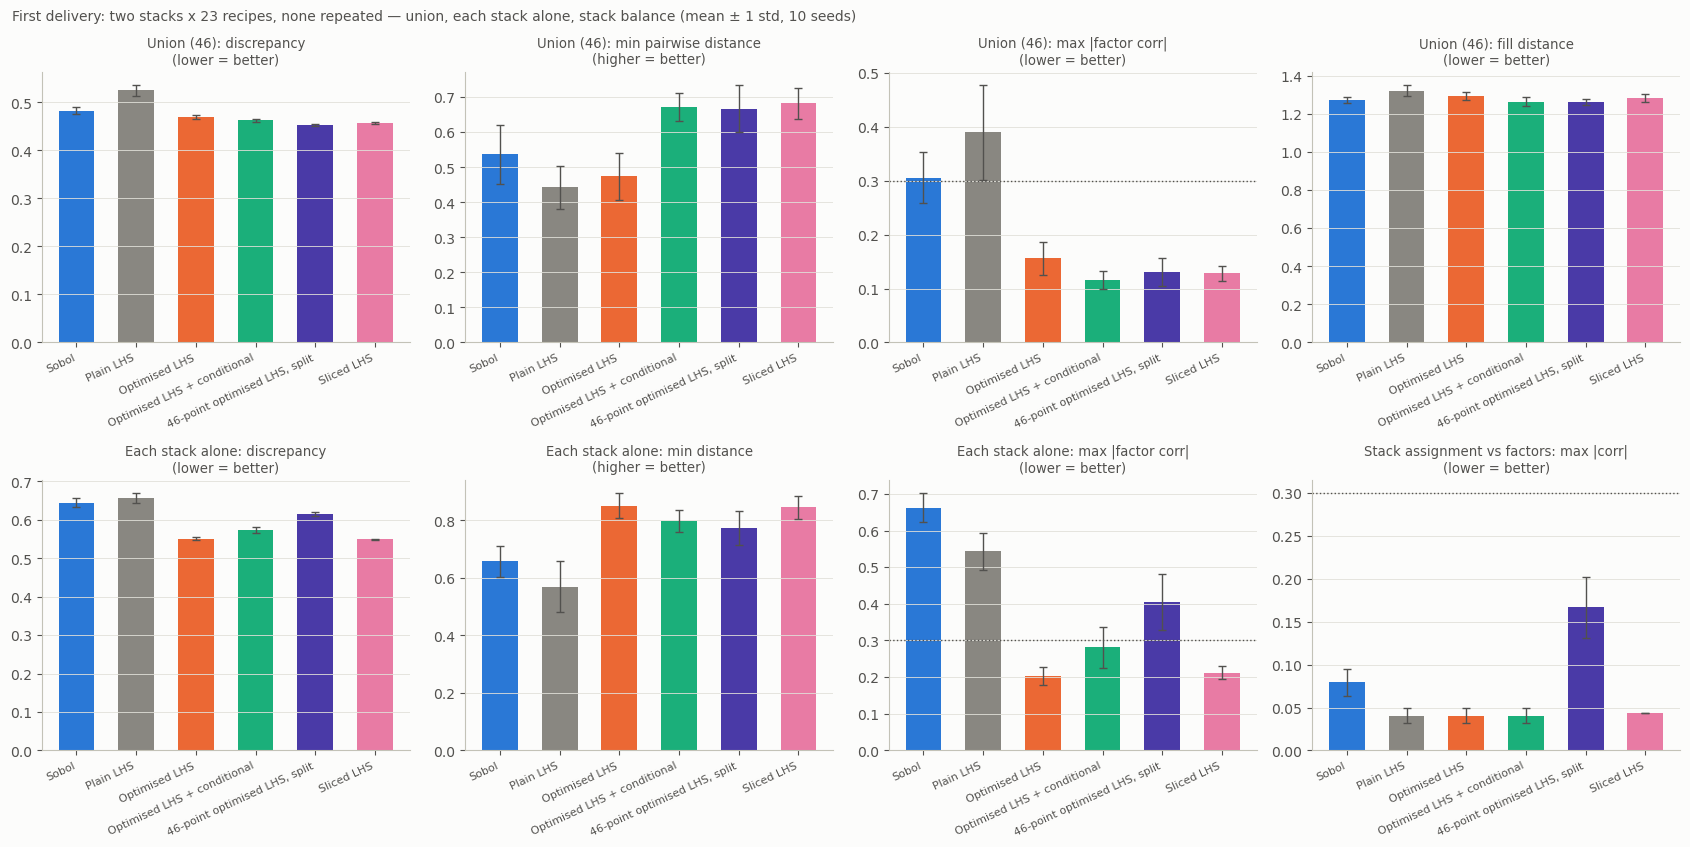

,method,union discrepancy,union min_dist,union max_corr,union fill_dist,per-stack discrepancy,per-stack min_dist,per-stack max_corr,stack balance |corr|
0,Sobol,0.483,0.537,0.306,1.272,0.645,0.658,0.663,0.079
1,Plain LHS,0.525,0.443,0.390,1.322,0.657,0.569,0.544,0.041
2,Optimised LHS,0.469,0.474,0.156,1.291,0.551,0.852,0.203,0.041
3,Optimised LHS + conditional,0.462,0.673,0.116,1.262,0.574,0.797,0.282,0.041
4,"46-point optimised LHS, split",0.453,0.668,0.131,1.262,0.616,0.774,0.404,0.167
5,Sliced LHS,0.458,0.683,0.129,1.283,0.549,0.846,0.212,0.044


In [6]:
def two_stack_designs(method, seed):
    # returns (A, B): the Al2O3 and TiO2 batches in the unit cube
    if method == 'Sobol':
        eng = qmc.Sobol(d=d, scramble=True, seed=seed); return eng.random(N_CONDITIONS), eng.random(N_CONDITIONS)
    if method == 'Plain LHS':
        return plain_lhs(N_CONDITIONS, d, seed), plain_lhs(N_CONDITIONS, d, seed + 1000)
    if method == 'Optimised LHS':
        return optimized_lhs(N_CONDITIONS, d, seed), optimized_lhs(N_CONDITIONS, d, seed + 1000)
    if method == 'Optimised LHS + conditional':
        A = optimized_lhs(N_CONDITIONS, d, seed); return A, conditional_optimized_lhs(_round_norm(A), N_CONDITIONS, d, seed + 1000)
    if method == 'Sliced LHS':
        return sliced_lhs(N_CONDITIONS, d, seed)
    if method == '46-point optimised LHS, split':
        W = optimized_lhs(2 * N_CONDITIONS, d, seed); rng = np.random.default_rng(seed); best = None
        for _ in range(200):
            idx = rng.permutation(2 * N_CONDITIONS); A, Bx = W[idx[:N_CONDITIONS]], W[idx[N_CONDITIONS:]]
            val = 0.5 * (discrepancy(_round_norm(A)) + discrepancy(_round_norm(Bx)))
            if best is None or val < best[0]: best = (val, A, Bx)
        return best[1], best[2]
    raise ValueError(method)

def two_stack_metrics(A, B):
    A, B = _round_norm(A), _round_norm(B); Uu = np.vstack([A, B]); ind = np.r_[np.zeros(len(A)), np.ones(len(B))]
    out = {f'union {q}': v for q, v in all_metrics(Uu).items()}
    mA, mB = all_metrics(A), all_metrics(B)
    out['per-stack discrepancy'] = 0.5 * (mA['discrepancy'] + mB['discrepancy'])
    out['per-stack min_dist'] = 0.5 * (mA['min_dist'] + mB['min_dist'])
    out['per-stack max_corr'] = 0.5 * (mA['max_corr'] + mB['max_corr'])
    out['stack balance |corr|'] = float(max(abs(np.corrcoef(ind, Uu[:, j])[0, 1]) for j in range(d)))
    return out

N_SEEDS_M = 10
res_2s = {m: [two_stack_metrics(*two_stack_designs(m, s_)) for s_ in range(N_SEEDS_M)] for m in METHOD_COLOURS}
KEYS_2S = list(next(iter(res_2s.values()))[0])
rows = []
for m, lst in res_2s.items():
    row = {'method': m}
    for q in KEYS_2S:
        vals = [r[q] for r in lst]; row[q] = round(float(np.mean(vals)), 4); row[q + '_std'] = round(float(np.std(vals)), 4)
    rows.append(row)
two_tbl = pd.DataFrame(rows)
save('two_stack_table', two_tbl)

PANELS_2S = [('union discrepancy', 'Union (46): discrepancy', 'lower = better'), ('union min_dist', 'Union (46): min pairwise distance', 'higher = better'),
             ('union max_corr', 'Union (46): max |factor corr|', 'lower = better'), ('union fill_dist', 'Union (46): fill distance', 'lower = better'),
             ('per-stack discrepancy', 'Each stack alone: discrepancy', 'lower = better'), ('per-stack min_dist', 'Each stack alone: min distance', 'higher = better'),
             ('per-stack max_corr', 'Each stack alone: max |factor corr|', 'lower = better'), ('stack balance |corr|', 'Stack assignment vs factors: max |corr|', 'lower = better')]
names = list(METHOD_COLOURS)
fig, axes = plt.subplots(2, 4, figsize=(17, 8.6))
for ax, (q, ylab, better) in zip(axes.ravel(), PANELS_2S):
    ax.bar(range(len(names)), two_tbl[q], yerr=two_tbl[q + '_std'], width=0.6, capsize=3, color=[METHOD_COLOURS[m] for m in names], error_kw=dict(ecolor=INK2, lw=1))
    if 'max_corr' in q or 'balance' in q:
        ax.axhline(0.3, ls=':', color=INK2, lw=1)
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=25, ha='right', fontsize=8)
    ax.set_title(f'{ylab}\n({better})', fontsize=9.5, color=INK2); ax.grid(axis='x', visible=False)
fig.suptitle(f'First delivery: two stacks x {N_CONDITIONS} recipes, none repeated — union, each stack alone, stack balance (mean ± 1 std, {N_SEEDS_M} seeds)',
             x=0.01, ha='left', fontsize=10, color=INK2)
fig.tight_layout(); save('two_stack_fig', fig); plt.show()
two_tbl[['method'] + KEYS_2S].round(3)

**Reading 2.1 (first delivery, 2 × 23, 10 seeds).**

| method | union discrepancy ↓ | union min dist ↑ | union max \|corr\| ↓ | union fill ↓ | each stack: discrepancy ↓ | each stack: min dist ↑ | each stack: max \|corr\| ↓ | stack balance ↓ |
|---|---|---|---|---|---|---|---|---|
| Sobol | 0.48 | 0.54 | 0.31 | 1.27 | 0.65 | 0.66 | 0.66 | 0.08 |
| Plain LHS | 0.53 | 0.44 | 0.39 | 1.32 | 0.66 | 0.57 | 0.54 | 0.04 |
| Optimised LHS (each batch on its own) | 0.47 | 0.47 | 0.16 | 1.29 | 0.55 | 0.85 | 0.20 | 0.04 |
| Optimised LHS + conditional | 0.46 | 0.67 | 0.12 | 1.26 | 0.57 | 0.80 | 0.28 | 0.04 |
| 46-point optimised LHS, split | 0.45 | 0.67 | 0.13 | 1.26 | 0.62 | 0.77 | 0.40 | 0.17 |
| **Sliced LHS (used)** | 0.46 | **0.68** | 0.13 | 1.28 | **0.55** | 0.85 | 0.21 | 0.04 |

* **Sobol and plain LHS fail the correlation guard**, on the union (0.31, 0.39) and badly on each stack alone (0.66, 0.54):
  a 23-point stretch of either leaves two factors confounded.
* **The 46-point split wins the union but loses the stacks**: its halves are not Latin hypercubes (max |corr| 0.40 per
  stack, balance 0.17), so a substrate modelled on its own would be worse off.
* **The sliced LHS is the only method that is best-or-equal in all three groups.** Union metrics equal to the best
  (discrepancy 0.46, closest pair 0.68 thanks to the maximin term, correlation 0.13), each stack as good as a standalone
  optimised LHS (0.55 / 0.85 / 0.21), and balance 0.04. It replaces "optimised LHS + conditional", which it beats on every
  per-stack metric (0.57 / 0.80 / 0.28) at equal union quality.

### 2.2 Future iterations: adding 23 recipes per stack each round

The same four generators when the campaign keeps going: round 1 is the first delivery (2 × 23 = 46), rounds 2 and 3 add
another 23 per stack each (92, 138 cumulative recipes). *Sobol* keeps drawing from its sequence; *plain LHS* and
*optimised LHS* draw fresh batches and pool them (each batch designed on its own); *optimised LHS + conditional* designs
every new batch in the gaps of everything fabricated so far; *sliced LHS* builds each round's pair of batches together,
with the union term of its objective including everything fabricated so far. Union metrics after each round, mean ± 1 std
over 3 seeds.

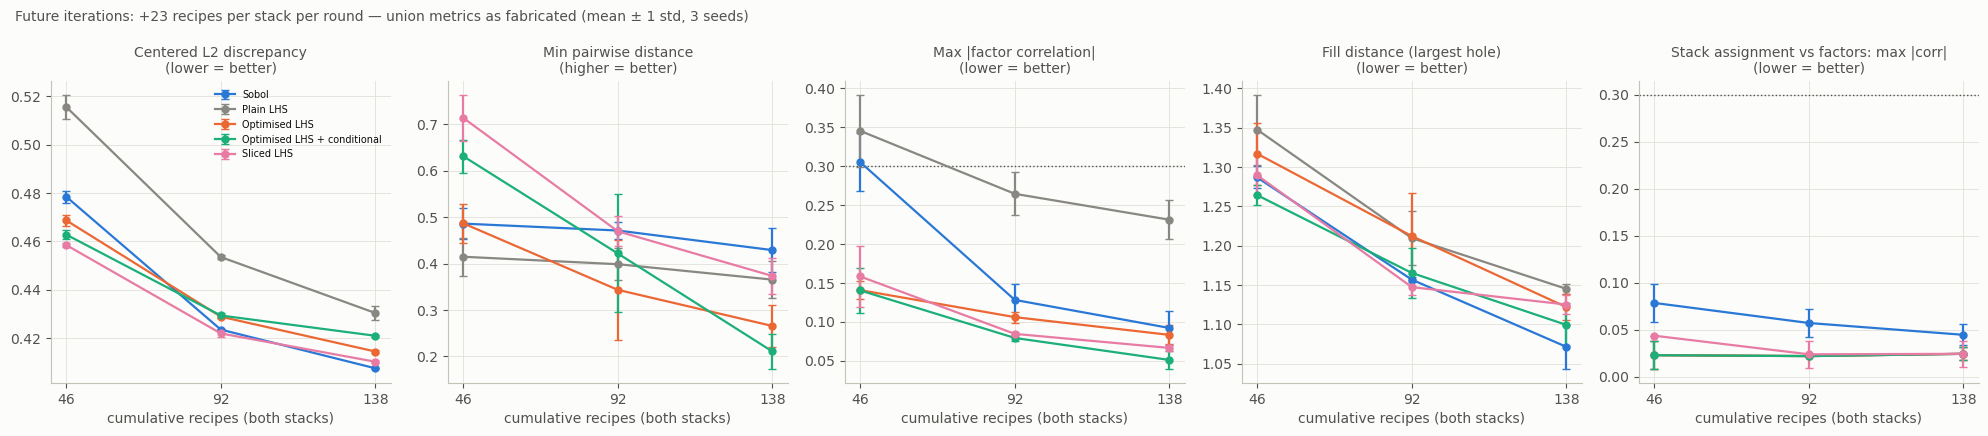

cumulative recipes,46,92,138
Sobol | discrepancy,0.4785,0.4235,0.4075
Sobol | min_dist,0.4860,0.4711,0.4289
Sobol | max_corr,0.3051,0.1281,0.0920
Sobol | fill_dist,1.2867,1.1568,1.0713
Sobol | stack balance |corr|,0.0784,0.0570,0.0444
Plain LHS | discrepancy,0.5157,0.4535,0.4303
Plain LHS | min_dist,0.4146,0.3985,0.3652
Plain LHS | max_corr,0.3453,0.2644,0.2311
Plain LHS | fill_dist,1.3474,1.2095,1.1450
Plain LHS | stack balance |corr|,0.0227,0.0217,0.0242


In [7]:
NB_ROUNDS, SEEDS_SEQ = 3, 3
ns = [2 * N_CONDITIONS * (r + 1) for r in range(NB_ROUNDS)]
SEQ_METHODS = ['Sobol', 'Plain LHS', 'Optimised LHS', 'Optimised LHS + conditional', 'Sliced LHS']
SM = {m: {q: np.zeros((SEEDS_SEQ, NB_ROUNDS)) for q in KEYS + ['stack balance |corr|']} for m in SEQ_METHODS}
for si in range(SEEDS_SEQ):
    eng = qmc.Sobol(d=d, scramble=True, seed=si)
    pools = {m: np.empty((0, d)) for m in SEQ_METHODS}; stacks = {m: np.empty(0) for m in SEQ_METHODS}
    for r in range(NB_ROUNDS):
        prev_sl = pools['Sliced LHS']
        sliced_pair = sliced_lhs(N_CONDITIONS, d, si * 100 + r * 10, fixed=_round_norm(prev_sl) if len(prev_sl) else None)
        for k in range(2):                                          # k = 0: Al2O3 batch, k = 1: TiO2 batch of this round
            seed_rk = si * 100 + r * 10 + k
            new = {'Sobol': eng.random(N_CONDITIONS),
                   'Plain LHS': plain_lhs(N_CONDITIONS, d, seed_rk),
                   'Optimised LHS': optimized_lhs(N_CONDITIONS, d, seed_rk),
                   'Optimised LHS + conditional': conditional_optimized_lhs(_round_norm(pools['Optimised LHS + conditional']), N_CONDITIONS, d, seed_rk),
                   'Sliced LHS': sliced_pair[k]}
            for m in SEQ_METHODS:
                pools[m] = np.vstack([pools[m], new[m]]); stacks[m] = np.r_[stacks[m], np.full(N_CONDITIONS, k)]
        for m in SEQ_METHODS:
            P = _round_norm(pools[m])
            for q, v in all_metrics(P).items():
                SM[m][q][si, r] = v
            SM[m]['stack balance |corr|'][si, r] = max(abs(np.corrcoef(stacks[m], P[:, j])[0, 1]) for j in range(d))

seq_tbl = pd.DataFrame({'cumulative recipes': ns})
for m in SEQ_METHODS:
    for q in KEYS + ['stack balance |corr|']:
        seq_tbl[f'{m} | {q}'] = SM[m][q].mean(0).round(4)
save('future_iterations_table', seq_tbl)

fig, axes = plt.subplots(1, 5, figsize=(20, 4.4))
for ax, q in zip(axes, KEYS + ['stack balance |corr|']):
    for m in SEQ_METHODS:
        ax.errorbar(ns, SM[m][q].mean(0), yerr=SM[m][q].std(0), marker='o', ms=5, lw=1.6, capsize=3, color=METHOD_COLOURS[m], label=m)
    if q in ('max_corr', 'stack balance |corr|'):
        ax.axhline(0.3, ls=':', color=INK2, lw=1)
    lab = PANEL_LABELS.get(q, ('Stack assignment vs factors: max |corr|', 'lower = better'))
    ax.set_xticks(ns); ax.set_xlabel('cumulative recipes (both stacks)'); ax.set_title(f'{lab[0]}\n({lab[1]})', fontsize=10, color=INK2)
axes[0].legend(fontsize=7, loc='upper right')
fig.suptitle(f'Future iterations: +{N_CONDITIONS} recipes per stack per round — union metrics as fabricated (mean ± 1 std, {SEEDS_SEQ} seeds)',
             x=0.01, ha='left', fontsize=10, color=INK2)
fig.tight_layout(); save('future_iterations_fig', fig); plt.show()
seq_tbl.set_index('cumulative recipes').T

9 of the 23 sapphire settings lie inside the new design space and are treated as known: [2, 5, 8, 9, 12, 14, 20, 22, 23]


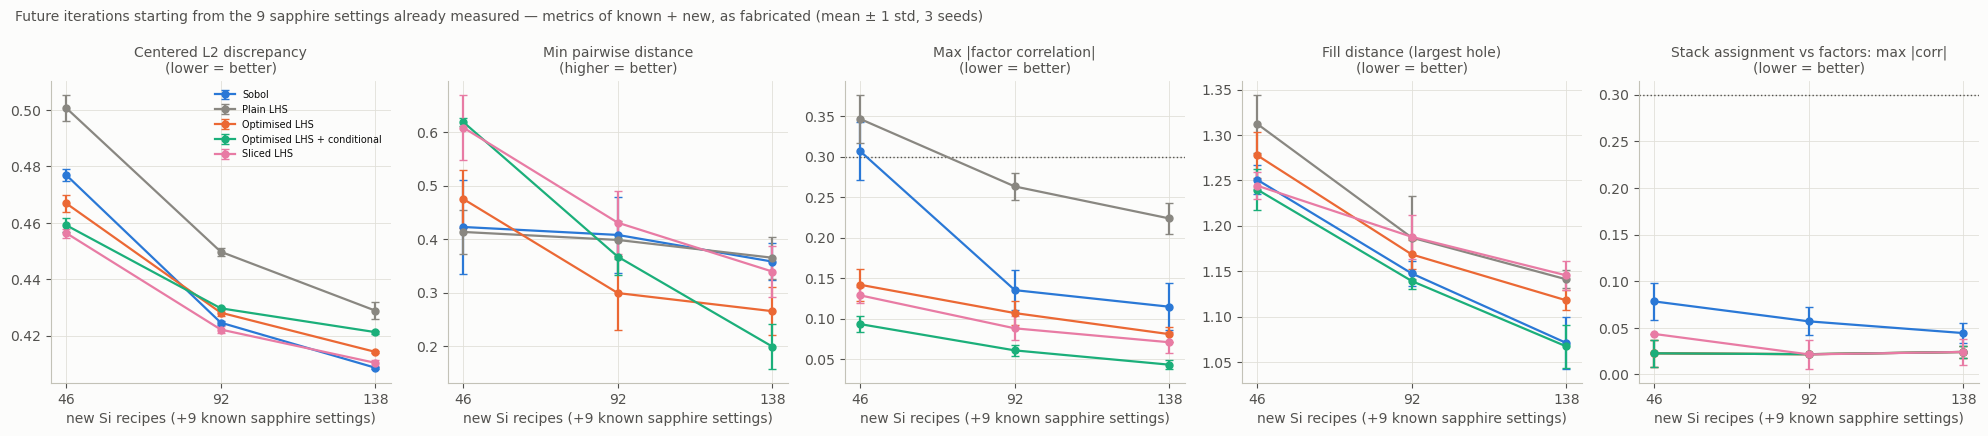

new Si recipes (cumulative),46,92,138
Sobol | discrepancy,0.4770,0.4246,0.4087
Sobol | min_dist,0.4227,0.4078,0.3580
Sobol | max_corr,0.3068,0.1352,0.1147
Sobol | fill_dist,1.2507,1.1475,1.0709
Sobol | stack balance |corr|,0.0784,0.0570,0.0444
Plain LHS | discrepancy,0.5007,0.4498,0.4289
Plain LHS | min_dist,0.4135,0.3985,0.3652
Plain LHS | max_corr,0.3466,0.2632,0.2237
Plain LHS | fill_dist,1.3122,1.1869,1.1410
Plain LHS | stack balance |corr|,0.0227,0.0217,0.0242


In [8]:
# Same study, but starting from what is already known: the sapphire settings (Hall + XRD in hand) that lie inside the new
# design space are part of the cloud from the start. Sobol / plain LHS / optimised LHS ignore them when generating;
# the conditional and sliced methods place every new batch around them. Metrics are on known + new recipes;
# the stack balance uses the new Si recipes only (the sapphire runs belong to neither stack).
_sap = pd.read_csv(SAPPHIRE_RUNS, sep='\t'); _sap = _sap.rename(columns={_sap.columns[0]: 'Base_Run_ID'})
_sap_c = _sap.groupby('Base_Run_ID')[FACTORS].first().reset_index()
_inside = _sap_c.apply(lambda row: all((row[f] in s_) if isinstance(s_, list) else (s_['min'] <= row[f] <= s_['max']) for f, s_ in CONFIG.items()), axis=1)
KNOWN = to_unit(_sap_c[_inside])                          # unit cube of the new bounds, not re-snapped
print(f'{len(KNOWN)} of the 23 sapphire settings lie inside the new design space and are treated as known: {_sap_c[_inside].Base_Run_ID.tolist()}')

SM_k = {m: {q: np.zeros((SEEDS_SEQ, NB_ROUNDS)) for q in KEYS + ['stack balance |corr|']} for m in SEQ_METHODS}
for si in range(SEEDS_SEQ):
    eng = qmc.Sobol(d=d, scramble=True, seed=si)
    pools = {m: np.empty((0, d)) for m in SEQ_METHODS}; stacks = {m: np.empty(0) for m in SEQ_METHODS}
    cloud = lambda m: np.vstack([KNOWN, _round_norm(pools[m])]) if len(pools[m]) else KNOWN
    for r in range(NB_ROUNDS):
        sliced_pair = sliced_lhs(N_CONDITIONS, d, si * 100 + r * 10, fixed=cloud('Sliced LHS'))
        for k in range(2):                                          # k = 0: Al2O3 batch, k = 1: TiO2 batch of this round
            seed_rk = si * 100 + r * 10 + k
            new = {'Sobol': eng.random(N_CONDITIONS),
                   'Plain LHS': plain_lhs(N_CONDITIONS, d, seed_rk),
                   'Optimised LHS': optimized_lhs(N_CONDITIONS, d, seed_rk),
                   'Optimised LHS + conditional': conditional_optimized_lhs(cloud('Optimised LHS + conditional'), N_CONDITIONS, d, seed_rk),
                   'Sliced LHS': sliced_pair[k]}
            for m in SEQ_METHODS:
                pools[m] = np.vstack([pools[m], new[m]]); stacks[m] = np.r_[stacks[m], np.full(N_CONDITIONS, k)]
        for m in SEQ_METHODS:
            for q, v in all_metrics(cloud(m)).items():
                SM_k[m][q][si, r] = v
            Pn = _round_norm(pools[m])
            SM_k[m]['stack balance |corr|'][si, r] = max(abs(np.corrcoef(stacks[m], Pn[:, j])[0, 1]) for j in range(d))

seq_k = pd.DataFrame({'new Si recipes (cumulative)': ns})
for m in SEQ_METHODS:
    for q in KEYS + ['stack balance |corr|']:
        seq_k[f'{m} | {q}'] = SM_k[m][q].mean(0).round(4)
save('future_iterations_known_table', seq_k)

fig, axes = plt.subplots(1, 5, figsize=(20, 4.4))
for ax, q in zip(axes, KEYS + ['stack balance |corr|']):
    for m in SEQ_METHODS:
        ax.errorbar(ns, SM_k[m][q].mean(0), yerr=SM_k[m][q].std(0), marker='o', ms=5, lw=1.6, capsize=3, color=METHOD_COLOURS[m], label=m)
    if q in ('max_corr', 'stack balance |corr|'):
        ax.axhline(0.3, ls=':', color=INK2, lw=1)
    lab = PANEL_LABELS.get(q, ('Stack assignment vs factors: max |corr|', 'lower = better'))
    ax.set_xticks(ns); ax.set_xlabel(f'new Si recipes (+{len(KNOWN)} known sapphire settings)'); ax.set_title(f'{lab[0]}\n({lab[1]})', fontsize=10, color=INK2)
axes[0].legend(fontsize=7, loc='upper right')
fig.suptitle(f'Future iterations starting from the {len(KNOWN)} sapphire settings already measured — metrics of known + new, as fabricated (mean ± 1 std, {SEEDS_SEQ} seeds)',
             x=0.01, ha='left', fontsize=10, color=INK2)
fig.tight_layout(); save('future_iterations_known_fig', fig); plt.show()
seq_k.set_index('new Si recipes (cumulative)').T

**Reading 2.2 (future rounds, cumulative 46 → 92 → 138, 3 seeds).**

| cumulative recipes | 46 | 92 | 138 |
|---|---|---|---|
| discrepancy: Sobol / oLHS / oLHS + cond. / sliced | 0.48 / 0.47 / 0.46 / **0.46** | 0.42 / 0.43 / 0.43 / **0.42** | **0.41** / 0.41 / 0.42 / 0.41 |
| min distance: same order | 0.49 / 0.49 / 0.63 / **0.71** | **0.47** / 0.34 / 0.42 / **0.47** | **0.43** / 0.27 / 0.21 / 0.37 |
| max \|corr\|: same order | 0.31 / 0.14 / 0.14 / 0.16 | 0.13 / 0.11 / **0.08** / **0.08** | 0.09 / 0.08 / **0.05** / 0.07 |
| fill distance: same order | 1.29 / 1.32 / **1.26** / 1.29 | 1.16 / 1.21 / 1.17 / **1.15** | **1.07** / 1.12 / 1.10 / 1.13 |

* **For the rounds that matter now, the sliced LHS leads.** Best discrepancy at 46 and 92, and the closest pair stays the
  highest of the LHS family through round 2 (0.71 → 0.47, level with Sobol): the maximin term does for later rounds what
  conditioning alone could not (optimised LHS + conditional falls to 0.42 and then 0.21).
* **Sobol overtakes at ~100+ recipes** on discrepancy, fill distance and minimum distance. That is its known asymptotic
  property; it becomes visible only after roughly six chamber loads per stack.
* **All optimised-LHS variants stay far under the 0.3 correlation guard** at every size, so correlation does not change the
  choice.
* Plain LHS is last on every metric at every size.

**Reading 2.2, starting from the known sapphire settings.** The 9 sapphire settings with Hall and XRD data that fall
inside the new design space (#2, #5, #8, #9, #12, #14, #20, #22, #23) are part of the cloud from the start.

| known + new Si recipes | 46 | 92 | 138 |
|---|---|---|---|
| discrepancy: Sobol / oLHS / oLHS + cond. / sliced | 0.48 / 0.47 / 0.46 / **0.46** | 0.42 / 0.43 / 0.43 / **0.42** | **0.41** / 0.41 / 0.42 / 0.41 |
| min distance: same order | 0.42 / 0.48 / **0.62** / 0.61 | 0.41 / 0.30 / 0.37 / **0.43** | **0.36** / 0.27 / 0.20 / 0.34 |
| max \|corr\|: same order | 0.31 / 0.14 / **0.09** / 0.13 | 0.14 / 0.11 / **0.06** / 0.09 | 0.11 / 0.08 / **0.04** / 0.07 |
| fill distance: same order | 1.25 / 1.28 / **1.24** / 1.24 | 1.15 / 1.17 / **1.14** / 1.19 | 1.07 / 1.12 / **1.07** / 1.15 |

* **The ranking does not change**: the sliced LHS has the best discrepancy in rounds 1 and 2 and Sobol catches up by
  round 3, exactly as without the known points.
* **The known points cost the unaware methods their closest pair.** Sobol's minimum distance falls from 0.49 to 0.42 in
  round 1 and the unconditional optimised LHS from 0.34 to 0.30 in round 2: a generator that does not see the sapphire
  settings sometimes lands a new recipe next to one. The two methods that condition on them keep the closest pair at
  0.61–0.62 in round 1, where it matters most.
* **Round 1 is where using the known settings pays.** By round 3 the 9 known points are 6 % of the cloud and every metric
  is within a hundredth or two of the version without them.
* This only applies if the sapphire data transfer to the Si base (§6). The run sheet in §3 does not condition on them.

### 2.3 The sapphire runs as known locations

The sapphire conditions inside the new design space carry the same Al₂O₃ touching layer. If their data transfer to the
Si base, they are locations already sampled; a design that ignores them may re-fabricate one. Here they are frozen and
23 (one stack) or 46 (two stacks, the second conditioned on the fixed runs *and* the first) new recipes are added,
unconditional optimised LHS vs conditional. Metrics on fixed + new, 5 seeds.

9 of 23 sapphire conditions lie inside the new design space and are used as fixed runs: [2, 5, 8, 9, 12, 14, 20, 22, 23]


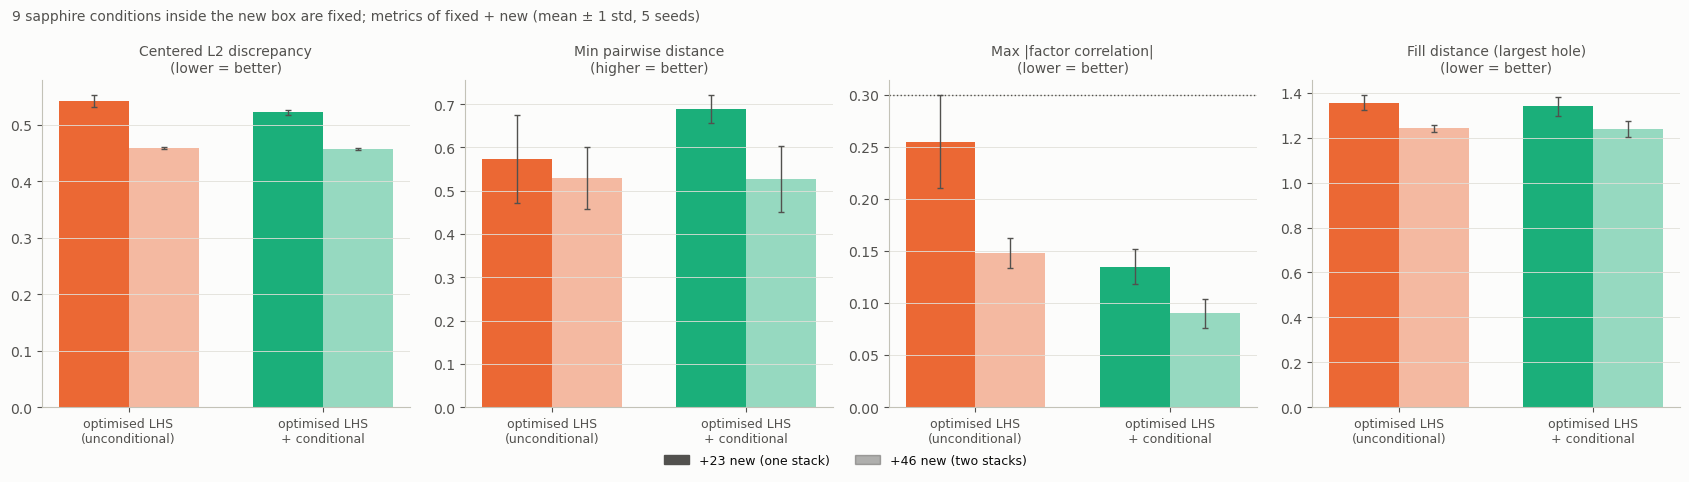

,method,case,discrepancy,min_dist,max_corr,fill_dist
0,Optimised LHS,+23 new (one stack),0.5416,0.5733,0.2550,1.3566
1,Optimised LHS,+46 new (two stacks),0.4584,0.5303,0.1480,1.2417
2,Optimised LHS + conditional,+23 new (one stack),0.5217,0.6886,0.1349,1.3404
3,Optimised LHS + conditional,+46 new (two stacks),0.4571,0.5265,0.0902,1.2388


In [9]:
sap = pd.read_csv(SAPPHIRE_RUNS, sep='\t')
sap = sap.rename(columns={sap.columns[0]: 'Base_Run_ID'})
sap['fail'] = sap['Hall mobility (cm^2/V*s)'].astype(str).str.contains('Fail')
sap_c = sap.groupby('Base_Run_ID').agg(**{f: (f, 'first') for f in FACTORS}, n_fail=('fail', 'sum')).reset_index()

def in_new_box(row):
    return all((row[f] in s_) if isinstance(s_, list) else (s_['min'] <= row[f] <= s_['max']) for f, s_ in CONFIG.items())

sap_in = sap_c[sap_c.apply(in_new_box, axis=1)]
FIXED = to_unit(sap_in)                                    # known locations, in the unit cube of the new bounds
print(f'{len(sap_in)} of 23 sapphire conditions lie inside the new design space and are used as fixed runs: '
      f'{sap_in.Base_Run_ID.tolist()}')

UNCOND, COND = 'Optimised LHS', 'Optimised LHS + conditional'
SEEDS_B = 5
N_NEW = {'+23 new (one stack)': 23, '+46 new (two stacks)': 46}
def new_points(method, n, seed):
    if method == UNCOND:
        return optimized_lhs(n, d, seed)
    first = conditional_optimized_lhs(FIXED, N_CONDITIONS, d, seed)
    if n == N_CONDITIONS:
        return first
    second = conditional_optimized_lhs(np.vstack([FIXED, _round_norm(first)]), N_CONDITIONS, d, seed + 500)
    return np.vstack([first, second])

rows = []
for m in (UNCOND, COND):
    for case, n in N_NEW.items():
        lst = [all_metrics(np.vstack([FIXED, _round_norm(new_points(m, n, s_))])) for s_ in range(SEEDS_B)]
        row = {'method': m, 'case': case}
        for q in KEYS:
            vals = [r[q] for r in lst]; row[q] = round(float(np.mean(vals)), 4); row[q + '_std'] = round(float(np.std(vals)), 4)
        rows.append(row)
cond_tbl = pd.DataFrame(rows)
save('sapphire_fixed_table', cond_tbl)

fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
names = [UNCOND, COND]; w = 0.36
for ax, q in zip(axes, KEYS):
    for i, (case, alpha) in enumerate(zip(N_NEW, (1.0, 0.45))):
        mu = [cond_tbl[(cond_tbl.method == m) & (cond_tbl.case == case)][q].iloc[0] for m in names]
        sd = [cond_tbl[(cond_tbl.method == m) & (cond_tbl.case == case)][q + '_std'].iloc[0] for m in names]
        ax.bar(np.arange(len(names)) + (i - 0.5) * w, mu, yerr=sd, width=w, capsize=2.5, alpha=alpha,
               color=[METHOD_COLOURS[m] for m in names], error_kw=dict(ecolor=INK2, lw=1))
    if q == 'max_corr':
        ax.axhline(0.3, ls=':', color=INK2, lw=1)
    ax.set_xticks(range(len(names))); ax.set_xticklabels(['optimised LHS\n(unconditional)', 'optimised LHS\n+ conditional'], fontsize=9)
    ax.set_title(f'{PANEL_LABELS[q][0]}\n({PANEL_LABELS[q][1]})', fontsize=10, color=INK2); ax.grid(axis='x', visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=INK2, alpha=a) for a in (1.0, 0.45)]
fig.legend(handles, list(N_NEW), fontsize=9, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.04))
fig.suptitle(f'{len(sap_in)} sapphire conditions inside the new box are fixed; metrics of fixed + new (mean ± 1 std, {SEEDS_B} seeds)',
             x=0.01, ha='left', fontsize=10, color=INK2)
fig.tight_layout(); save('sapphire_fixed_fig', fig); plt.show()
cond_tbl[['method', 'case'] + KEYS]

**Reading 2.3 (9 sapphire runs fixed: #2, #5, #8, #9, #12, #14, #20, #22, #23; 5 seeds).**

| fixed + new | discrepancy ↓ | min distance ↑ | max \|corr\| ↓ | fill distance ↓ |
|---|---|---|---|---|
| +23, optimised LHS (unconditional) | 0.54 | 0.57 | 0.26 | 1.36 |
| +23, optimised LHS + conditional | 0.52 | 0.69 | 0.13 | 1.34 |
| +46, optimised LHS (unconditional) | 0.46 | 0.53 | 0.15 | 1.24 |
| +46, optimised LHS + conditional | 0.46 | 0.53 | 0.09 | 1.24 |

Conditioning on the sapphire locations helps for the one-stack case, most on the minimum distance (0.69 vs 0.57) and the
correlation (0.13 vs 0.26): no new recipe is placed next to a sapphire one. With 46 new recipes the two are level except
for correlation, since 46 points fill the space regardless. **The run sheet does not use the sapphire runs as fixed
points**: that is only right if their data transfer to the Si base, which is unproven until the first Si batch returns
(§6). If it holds, the second round should freeze them together with the fabricated Si runs.

### 2.4 A small extra check: pick the new batch from a pool of candidates

Instead of moving 23 new points around (the column swaps), draw a large **pool** of admissible candidates first and
**select** the 23 that best complement the fixed runs: a 500-point optimised LHS snapped to the tool grid, greedy forward
selection on the discrepancy of fixed + selected, then exchange passes. Constraints or vetoes could be applied to the pool
before selection; the selected batch is no longer a Latin hypercube. Same setting as 2.3, +23 new, 5 seeds.

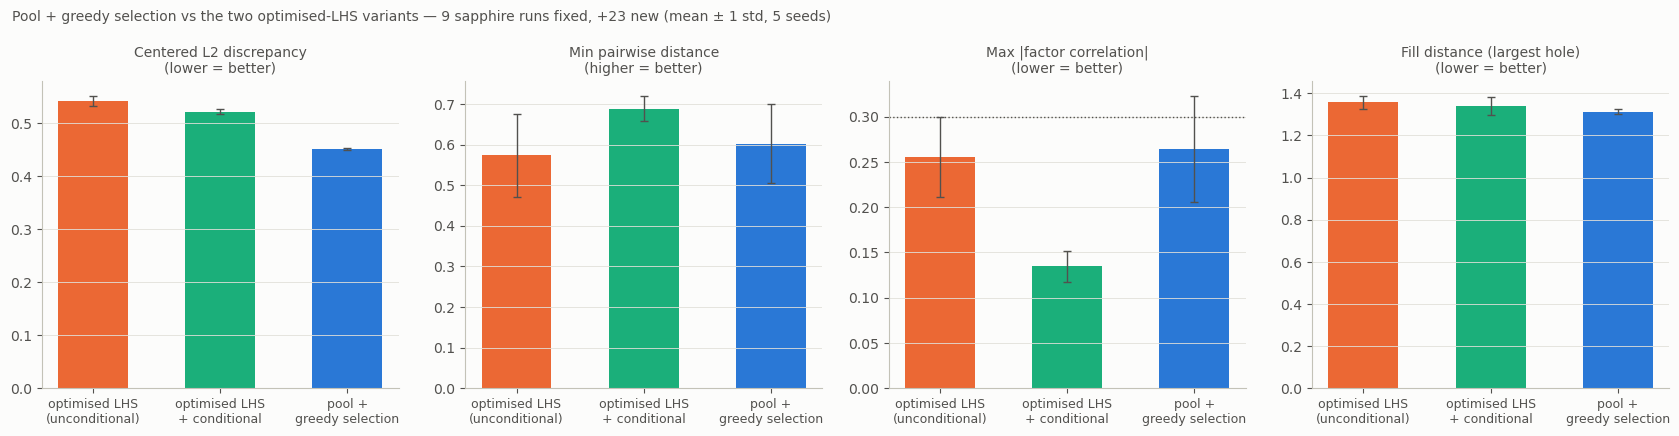

,method,discrepancy,min_dist,max_corr,fill_dist
0,Optimised LHS,0.5416,0.5733,0.2550,1.3566
1,Optimised LHS + conditional,0.5217,0.6886,0.1349,1.3404
2,Pool + greedy selection,0.4511,0.6021,0.2642,1.3129


In [10]:
def pool_greedy_selection(fixed, n_new, dim, seed, pool_size=500, exchange_passes=3):
    pool = np.unique(_round_norm(optimized_lhs(pool_size, dim, seed)), axis=0)     # fabricable candidates, no duplicates
    def score(idx):
        return qmc.discrepancy(np.vstack([fixed, pool[idx]]) if len(fixed) else pool[idx])
    chosen, remaining = [], list(range(len(pool)))
    for _ in range(n_new):                                                        # greedy forward selection
        best_i = min(remaining, key=lambda i: score(chosen + [i]))
        chosen.append(best_i); remaining.remove(best_i)
    for _ in range(exchange_passes):                                              # exchange refinement
        improved = False
        for j in range(n_new):
            others = chosen[:j] + chosen[j + 1:]
            best_i = min(remaining + [chosen[j]], key=lambda i: score(others + [i]))
            if best_i != chosen[j]:
                remaining.append(chosen[j]); remaining.remove(best_i); chosen[j] = best_i; improved = True
        if not improved:
            break
    return pool[chosen]

POOL = 'Pool + greedy selection'
TRIO = {UNCOND: METHOD_COLOURS[UNCOND], COND: METHOD_COLOURS[COND], POOL: BLUE}
rows = []
for m in TRIO:
    lst = [all_metrics(np.vstack([FIXED, _round_norm(pool_greedy_selection(FIXED, N_CONDITIONS, d, s_) if m == POOL else new_points(m, N_CONDITIONS, s_))]))
           for s_ in range(SEEDS_B)]
    row = {'method': m}
    for q in KEYS:
        vals = [r[q] for r in lst]; row[q] = round(float(np.mean(vals)), 4); row[q + '_std'] = round(float(np.std(vals)), 4)
    rows.append(row)
pool_tbl = pd.DataFrame(rows)
save('pool_check_table', pool_tbl)

fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
names = list(TRIO)
for ax, q in zip(axes, KEYS):
    ax.bar(range(len(names)), pool_tbl[q], yerr=pool_tbl[q + '_std'], width=0.55, capsize=3, color=[TRIO[m] for m in names], error_kw=dict(ecolor=INK2, lw=1))
    if q == 'max_corr':
        ax.axhline(0.3, ls=':', color=INK2, lw=1)
    ax.set_xticks(range(len(names))); ax.set_xticklabels(['optimised LHS\n(unconditional)', 'optimised LHS\n+ conditional', 'pool +\ngreedy selection'], fontsize=9)
    ax.set_title(f'{PANEL_LABELS[q][0]}\n({PANEL_LABELS[q][1]})', fontsize=10, color=INK2); ax.grid(axis='x', visible=False)
fig.suptitle(f'Pool + greedy selection vs the two optimised-LHS variants — {len(sap_in)} sapphire runs fixed, +{N_CONDITIONS} new (mean ± 1 std, {SEEDS_B} seeds)',
             x=0.01, ha='left', fontsize=10, color=INK2)
fig.tight_layout(); save('pool_check_fig', fig); plt.show()
pool_tbl[['method'] + KEYS]

**Reading 2.4 (pool + greedy selection, 9 sapphire runs fixed, +23, 5 seeds).**

| method | discrepancy ↓ | min distance ↑ | max \|corr\| ↓ | fill distance ↓ |
|---|---|---|---|---|
| Optimised LHS (unconditional) | 0.54 | 0.57 | 0.26 | 1.36 |
| Optimised LHS + conditional | 0.52 | 0.69 | 0.13 | 1.34 |
| Pool + greedy selection | 0.45 | 0.60 | 0.26 | 1.31 |

The pool method wins the objective it optimises, discrepancy and the largest hole, because a fresh candidate can go
wherever the combined coverage gains most. It does not improve factor correlation, 0.26, twice the conditional design's,
because dropping the Latin structure removes what keeps the columns orthogonal. It is the better tool once a batch has to
respect constraints or vetoes, which is likely for a later Si round, but it needs a correlation term in the objective
first. Not used for the run sheet.

## 3. Generate the design with the chosen generator (optimised LHS)

`METHOD` selects the generator. Default: **sliced LHS** (§2.1/2.2) — the Al₂O₃ and TiO₂ batches are built together so that
the union of 46 recipes is a 46-point Latin hypercube and each stack's 23 is a 23-point Latin hypercube; the best of 10
seeds is kept (lowest union discrepancy among those whose union and both slices clear max |factor correlation| < 0.3).
No recipe is fabricated twice; the touching-layer effect is estimated by the model (stack as an 11th, two-level input),
and the table below checks that the stack assignment is balanced against every factor.

Alternatives: `'Optimised LHS'` — the Al₂O₃ batch is scipy's optimised LHS (best of 10 seeds) and the TiO₂ batch is placed
in its gaps by the conditional optimiser (or, with `PAIRED_DESIGNS = True`, the same 23 recipes on both stacks); `'Sobol'`,
`'Plain LHS'` likewise.

In [11]:
METHOD = 'Sliced LHS'      # both batches built together (see §2); alternatives: 'Optimised LHS' (+ conditional TiO2 batch), 'Sobol', 'Plain LHS'
GENERATORS = {'Optimised LHS': lambda s_: optimized_lhs(N_CONDITIONS, d, s_),
              'Plain LHS':     lambda s_: plain_lhs(N_CONDITIONS, d, s_),
              'Sobol':         lambda s_: qmc.Sobol(d=d, scramble=True, seed=s_).random(N_CONDITIONS)}
SEED2 = None
if METHOD == 'Sliced LHS':
    # 10 sliced designs; keep the one with the lowest union discrepancy among those whose union and both slices clear |r| < 0.3
    trials = [sliced_lhs(N_CONDITIONS, d, s_) for s_ in range(N_SEEDS_M)]
    scored = [(s_, two_stack_metrics(A_, B_)) for s_, (A_, B_) in enumerate(trials)]
    ok = [t for t in scored if t[1]['union max_corr'] < 0.3 and t[1]['per-stack max_corr'] < 0.3] or scored
    SEED = min(ok, key=lambda t: t[1]['union discrepancy'])[0]
    U = {'AlSi': trials[SEED][0], 'TiSi': trials[SEED][1]}
    print(f'Sliced LHS: seed {SEED} chosen among {N_SEEDS_M} ({len(ok)} clear the |r| < 0.3 guard on the union and on both slices)')
else:
    U_store = {METHOD: [GENERATORS[METHOD](s_) for s_ in range(N_SEEDS_M)]}          # 10 candidate Al2O3 batches
    res = {METHOD: [all_metrics(_round_norm(U_)) for U_ in U_store[METHOD]]}
    ok = [(s, r) for s, r in enumerate(res[METHOD]) if r['max_corr'] < 0.3]
    pool = ok if ok else list(enumerate(res[METHOD]))
    SEED = min(pool, key=lambda t: t[1]['discrepancy'])[0]
    U = {'AlSi': U_store[METHOD][SEED]}
    print(f'{METHOD}: seed {SEED} chosen among {N_SEEDS_M} ({len(ok)} seeds clear the |r| < 0.3 guard)')
if METHOD == 'Sliced LHS':
    pass
elif PAIRED_DESIGNS:
    U['TiSi'] = U['AlSi'].copy()
else:
    # TiO2 batch: conditional optimised LHS placed in the gaps of the Al2O3 batch. Several seeds are tried and the one
    # with the lowest union discrepancy is kept, subject to the TiO2 batch clearing the |r| < 0.3 guard on its own.
    A = _round_norm(U['AlSi'])
    trials = []
    for s2 in range(N_SEEDS_M):
        Bc = conditional_optimized_lhs(A, N_CONDITIONS, d, 1000 + s2)
        Bq = _round_norm(Bc)
        trials.append((s2, Bc, qmc.discrepancy(np.vstack([A, Bq])), max_factor_correlation(Bq)))
    ok2 = [t for t in trials if t[3] < 0.3] or trials
    SEED2, U['TiSi'], _, _ = min(ok2, key=lambda t: t[2])
    print(f'TiO2 batch: conditional seed {SEED2} chosen among {N_SEEDS_M} ({len([t for t in trials if t[3] < 0.3])} clear the |r| < 0.3 guard on their own)')

designs = {}
for k, u in U.items():
    dsg = to_physical(u)
    dsg.insert(0, 'Base_Run_ID', range(1, N_CONDITIONS + 1))
    dsg.insert(1, 'Stack', STACKS[k])
    dsg.insert(2, 'Sample_ID', [f'{k}-{i:02d}' for i in dsg.Base_Run_ID])
    designs[k] = dsg
P_al, P_ti = to_unit(designs['AlSi']), to_unit(designs['TiSi'])
P_union = np.vstack([P_al, P_ti])
used = all_metrics(P_al)
print(f'{N_CONDITIONS} conditions per stack, ' + ('built together as a sliced LHS - no recipe repeated' if METHOD == 'Sliced LHS' else
      'identical' if PAIRED_DESIGNS else 'distinct - TiO2 batch fills the gaps of the Al2O3 batch'))

# metrics of each stack alone and of the union; balance of the stack assignment against every factor
stack_tbl = pd.DataFrame({'Al2O3-on-Si alone (23)': all_metrics(P_al), 'TiO2-on-Si alone (23)': all_metrics(P_ti),
                          'union (46 distinct recipes)': all_metrics(P_union)}).T.round(3)
stack_ind = np.r_[np.zeros(len(P_al)), np.ones(len(P_ti))]
balance = pd.Series({f: float(np.corrcoef(stack_ind, P_union[:, i])[0, 1]) for i, f in enumerate(VARYING)}, name='corr(stack, factor)').round(2)
print('\nlargest |correlation| between the stack indicator and any factor:', float(balance.abs().max()), '(0 = perfectly balanced)')
display(stack_tbl)
balance.to_frame().T

Sliced LHS: seed 2 chosen among 10 (10 clear the |r| < 0.3 guard on the union and on both slices)
23 conditions per stack, built together as a sliced LHS - no recipe repeated

largest |correlation| between the stack indicator and any factor: 0.04 (0 = perfectly balanced)


,discrepancy,min_dist,max_corr,fill_dist
Al2O3-on-Si alone (23),0.549,0.769,0.235,1.387
TiO2-on-Si alone (23),0.546,0.884,0.208,1.364
union (46 distinct recipes),0.454,0.667,0.106,1.316


,Dep Power (W),O2 Flow (sccm),Dep Press (mTorr),Dep Temp (°C),Ox Temp (°C),Ox Press (atm),Ox Time (min),Vac Ann Temp (°C),Vac Ann Time (min),Dep Thickness (nm)
"corr(stack, factor)",0.0,-0.01,0.01,-0.04,0.0,0.04,0.01,0.0,-0.0,0.01


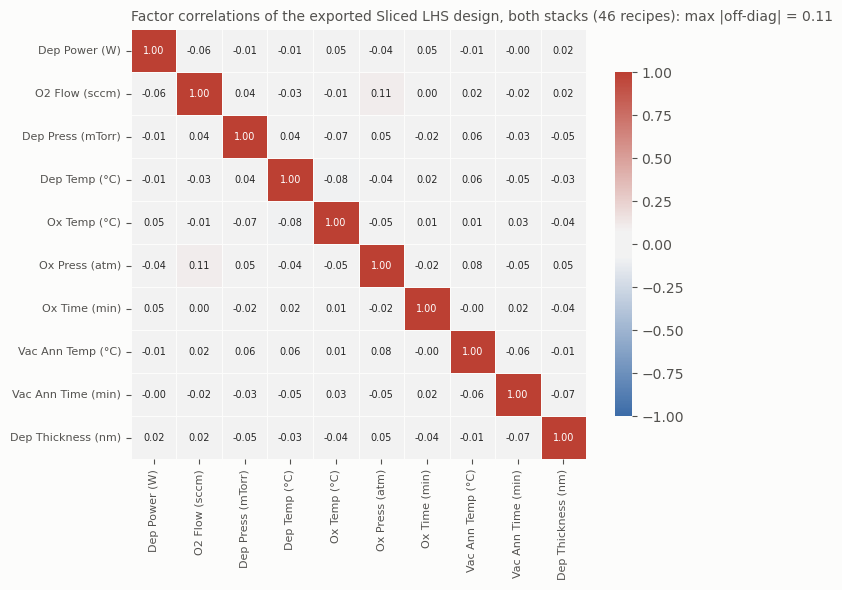

In [12]:
import seaborn as sns
# 1) factor correlations of the full exported design (union of both stacks, 46 recipes)
CMAP = sns.diverging_palette(250, 15, s=75, l=45, sep=20, as_cmap=True)
Cm = pd.DataFrame(np.corrcoef(P_union, rowvar=False), index=VARYING, columns=VARYING)
fig, ax = plt.subplots(figsize=(7.2, 6))
sns.heatmap(Cm, vmin=-1, vmax=1, cmap=CMAP, center=0, annot=True, fmt='.2f', annot_kws={'size': 7},
            cbar_kws={'shrink': 0.8}, linewidths=0.5, linecolor='#fcfcfb', ax=ax)
ax.set_title(f'Factor correlations of the exported {METHOD} design, both stacks ({2 * N_CONDITIONS} recipes): '
             f'max |off-diag| = {max_factor_correlation(P_union):.2f}', loc='left', fontsize=10, color=INK2)
ax.tick_params(labelsize=8); ax.grid(False)
fig.tight_layout(); save('correlation_fig', fig); plt.show()

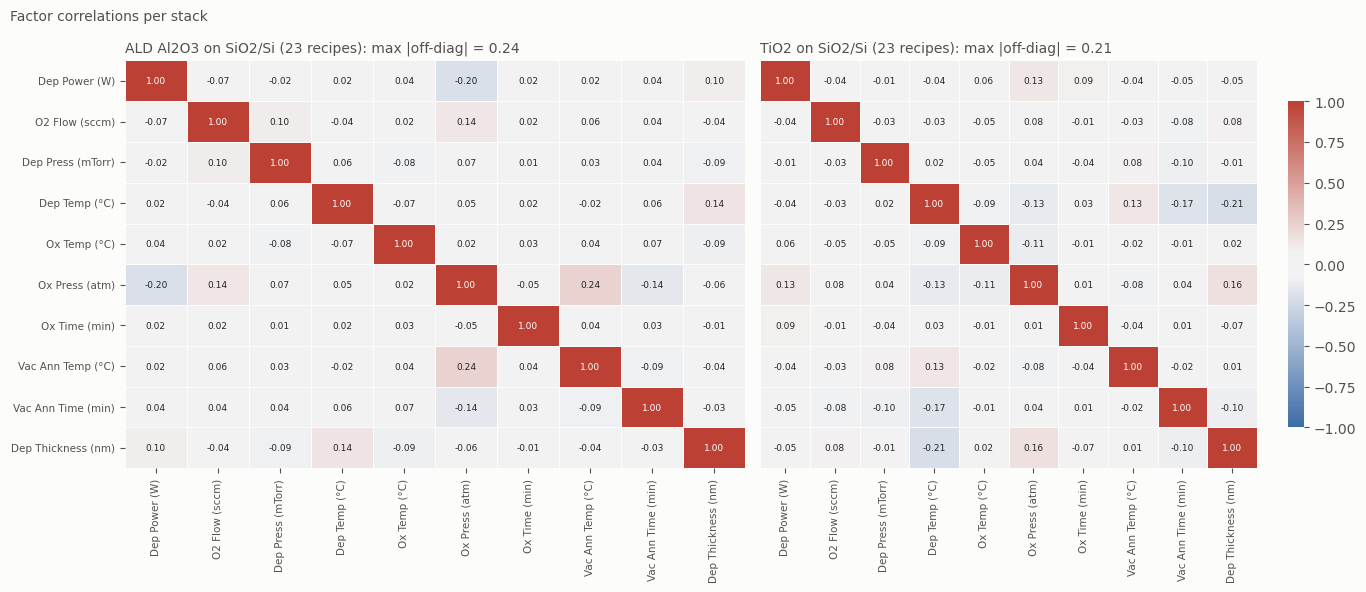

In [13]:
# 2) the same per stack: each substrate / top-layer configuration on its own
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, k, P in zip(axes, ['AlSi', 'TiSi'], [P_al, P_ti]):
    Cm = pd.DataFrame(np.corrcoef(P, rowvar=False), index=VARYING, columns=VARYING)
    sns.heatmap(Cm, vmin=-1, vmax=1, cmap=CMAP, center=0, annot=True, fmt='.2f', annot_kws={'size': 6.5},
                cbar=(ax is axes[-1]), cbar_kws={'shrink': 0.8}, linewidths=0.5, linecolor='#fcfcfb', ax=ax,
                yticklabels=(ax is axes[0]))
    ax.set_title(f'{STACKS[k]} ({N_CONDITIONS} recipes): max |off-diag| = {max_factor_correlation(P):.2f}', loc='left', fontsize=10, color=INK2)
    ax.tick_params(labelsize=7.5); ax.grid(False)
fig.suptitle('Factor correlations per stack', x=0.01, ha='left', fontsize=10, color=INK2)
fig.tight_layout(); save('correlation_per_stack_fig', fig); plt.show()

## 4. Coverage, and where the sapphire data sit relative to the new box

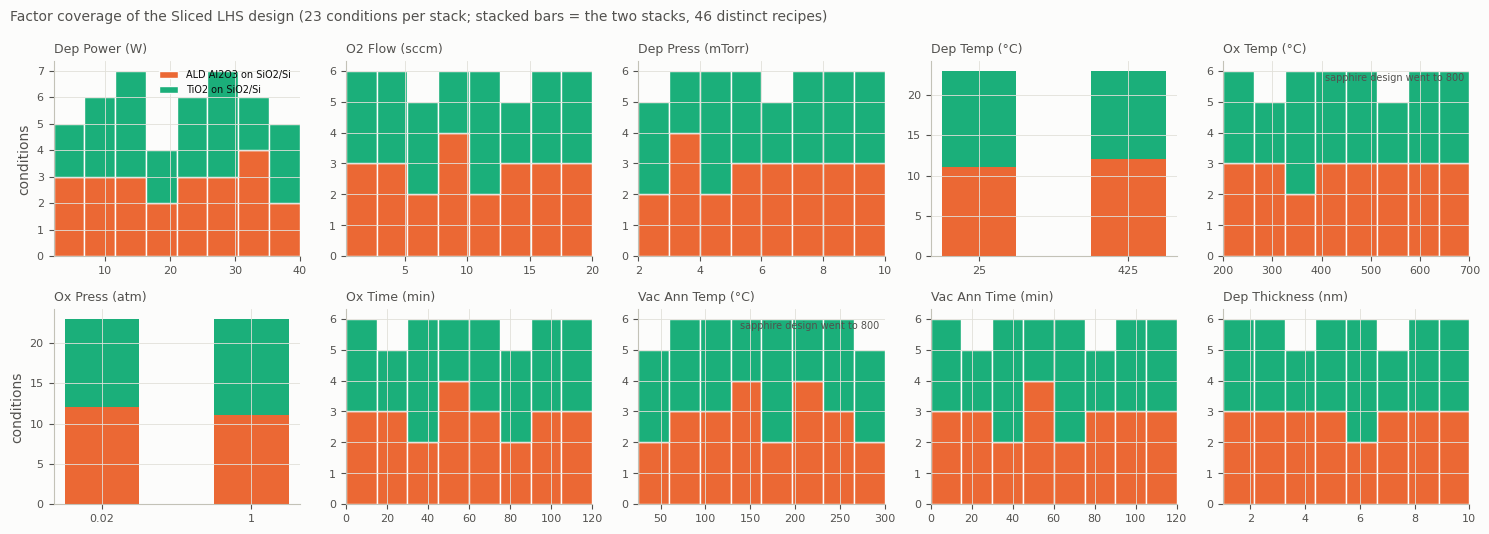

In [14]:
dsg = designs['AlSi']
STACK_COL = {'AlSi': ORANGE, 'TiSi': AQUA}
fig, axes = plt.subplots(2, 5, figsize=(15, 5.4))
for ax, f in zip(axes.ravel(), FACTORS):
    s = CONFIG[f]
    bottom = None
    for k in (['AlSi'] if (PAIRED_DESIGNS and METHOD != 'Sliced LHS') else ['AlSi', 'TiSi']):
        if isinstance(s, list):
            levels = [f'{v:g}' for v in s]; counts = np.array([int((designs[k][f] == v).sum()) for v in s])
            ax.bar(levels, counts, bottom=bottom, color=STACK_COL[k], width=0.5, label=STACKS[k]); bottom = counts if bottom is None else bottom + counts
        else:
            counts, edges = np.histogram(designs[k][f], bins=8, range=(s['min'], s['max']))
            ax.bar(edges[:-1], counts, bottom=bottom, width=np.diff(edges), align='edge', color=STACK_COL[k], edgecolor='#fcfcfb', label=STACKS[k])
            bottom = counts if bottom is None else bottom + counts
            ax.set_xlim(s['min'], s['max'])
    ax.set_title(f, fontsize=9, loc='left', color=INK2); ax.tick_params(labelsize=8)
    if f in SAPPHIRE and not isinstance(SAPPHIRE[f], str) and not isinstance(s, list) and SAPPHIRE[f][1] > s['max']:
        ax.annotate(f'sapphire design went to {SAPPHIRE[f][1]:g}', xy=(0.98, 0.9), xycoords='axes fraction', ha='right', fontsize=7, color=INK2)
axes[0, 0].set_ylabel('conditions'); axes[1, 0].set_ylabel('conditions'); axes[0, 0].legend(fontsize=7, loc='upper right')
fig.suptitle(f'Factor coverage of the {METHOD} design ({N_CONDITIONS} conditions per stack' + ('; both stacks identical)' if PAIRED_DESIGNS else '; stacked bars = the two stacks, 46 distinct recipes)'),
             x=0.01, ha='left', fontsize=10, color=INK2)
fig.tight_layout(); save('distributions_fig', fig); plt.show()

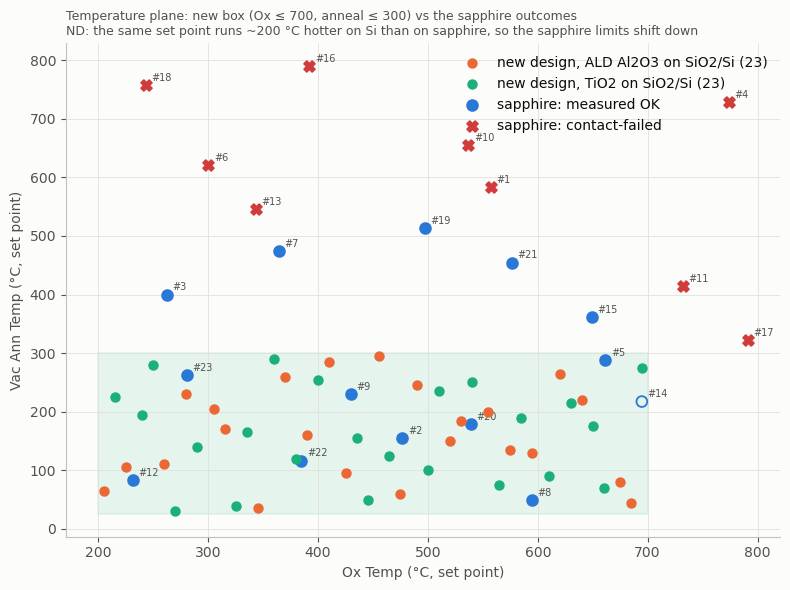

In [15]:
# sapphire outcomes in the temperature plane (set-point units) vs the new box
sap = pd.read_csv(SAPPHIRE_RUNS, sep='\t')
sap = sap.rename(columns={sap.columns[0]: 'Base_Run_ID'})
sap['fail'] = sap['Hall mobility (cm^2/V*s)'].astype(str).str.contains('Fail')
sap_c = sap.groupby('Base_Run_ID').agg(**{f: (f, 'first') for f in FACTORS}, n_fail=('fail', 'sum')).reset_index()
sap_c['outcome'] = np.where(sap_c.n_fail == 3, 'contact-failed (all 3)', np.where(sap_c.n_fail == 0, 'measured OK', 'partly failed'))

fig, ax = plt.subplots(figsize=(8, 6))
ax.add_patch(Rectangle((CONFIG['Ox Temp (°C)']['min'], CONFIG['Vac Ann Temp (°C)']['min']),
                       OX_TEMP_MAX - CONFIG['Ox Temp (°C)']['min'], VAC_ANN_MAX - CONFIG['Vac Ann Temp (°C)']['min'],
                       facecolor=AQUA, alpha=0.10, edgecolor=AQUA, lw=1.2, zorder=1))
for k in (['AlSi'] if (PAIRED_DESIGNS and METHOD != 'Sliced LHS') else ['AlSi', 'TiSi']):
    ax.scatter(designs[k]['Ox Temp (°C)'], designs[k]['Vac Ann Temp (°C)'], s=42, color=STACK_COL[k], zorder=4,
               label=f'new design, {STACKS[k]} ({N_CONDITIONS})' + (' = both stacks' if (PAIRED_DESIGNS and METHOD != 'Sliced LHS') else ''))
for out, mk, c, lab in [('measured OK', 'o', BLUE, 'sapphire: measured OK'), ('partly failed', 'o', BLUE, None),
                        ('contact-failed (all 3)', 'X', FAIL, 'sapphire: contact-failed')]:
    s_ = sap_c[sap_c.outcome == out]
    ax.scatter(s_['Ox Temp (°C)'], s_['Vac Ann Temp (°C)'], marker=mk, s=60, facecolor='none' if out == 'partly failed' else c,
               edgecolor=c, lw=1.3, zorder=3, label=lab)
for _, r in sap_c.iterrows():
    ax.annotate(f'#{int(r.Base_Run_ID)}', (r['Ox Temp (°C)'], r['Vac Ann Temp (°C)']), xytext=(4, 3), textcoords='offset points', fontsize=7, color=INK2)
ax.set_xlabel('Ox Temp (°C, set point)'); ax.set_ylabel('Vac Ann Temp (°C, set point)')
ax.set_title(f'Temperature plane: new box (Ox ≤ {OX_TEMP_MAX:g}, anneal ≤ {VAC_ANN_MAX:g}) vs the sapphire outcomes\n'
             'ND: the same set point runs ~200 °C hotter on Si than on sapphire, so the sapphire limits shift down', loc='left', fontsize=9, color=INK2)
ax.legend(loc='upper right')
fig.tight_layout(); save('temperature_plane_fig', fig); plt.show()

In [16]:
# how many usable sapphire conditions fall inside the new box (same Al2O3 touching layer -> candidates for a shared model)
def inside(row):
    return all((row[f] in s) if isinstance(s, list) else (s['min'] <= row[f] <= s['max']) for f, s in CONFIG.items())
usable = sap_c[sap_c.n_fail < 3].copy()
usable['inside_new_box'] = usable.apply(inside, axis=1)
usable['violates'] = usable.apply(lambda r: ', '.join(f for f, s in CONFIG.items()
                                  if not ((r[f] in s) if isinstance(s, list) else (s['min'] <= r[f] <= s['max']))), axis=1)
print(f"{int(usable.inside_new_box.sum())} of {len(usable)} usable sapphire conditions lie inside the new design space")
usable[['Base_Run_ID', 'Dep Temp (°C)', 'Ox Temp (°C)', 'Vac Ann Temp (°C)', 'Dep Thickness (nm)', 'inside_new_box', 'violates']].reset_index(drop=True)

9 of 14 usable sapphire conditions lie inside the new design space


,Base_Run_ID,Dep Temp (°C),Ox Temp (°C),Vac Ann Temp (°C),Dep Thickness (nm),inside_new_box,violates
0,2,25,476.8,155.4,5.1,True,
1,3,425,262.5,400.0,2.2,False,Vac Ann Temp (°C)
2,5,25,661.6,288.6,3.5,True,
3,7,25,364.3,474.1,8.6,False,Vac Ann Temp (°C)
4,8,425,594.5,48.9,1.7,True,
5,9,425,429.6,229.6,9.6,True,
6,12,25,231.1,83.7,6.9,True,
7,14,425,694.7,217.4,7.8,True,
8,15,25,649.3,362.2,6.2,False,Vac Ann Temp (°C)
9,19,25,497.4,512.8,1.9,False,Vac Ann Temp (°C)


## 5. The run sheets (written only when `SAVE_OUTPUTS = True`)

One workbook, campaign format: a `design_full` (3 replicates) and `design_unique` sheet per stack, an `all_full` sheet
with both stacks, plus `config`, `bounds_vs_sapphire`, `method_comparison` and `provenance`. Sample IDs are
`AlSi-07-r2` / `TiSi-07-r2` (stack – condition – replicate), so a delivery cannot be confused with the sapphire IDs `02_07`
or the HfO₂ IDs.

In [17]:
METHOD_TAG = {'Sliced LHS': 'sliced', 'Optimised LHS': 'oLHS', 'Sobol': 'Sobol', 'Plain LHS': 'LHS'}[METHOD]
full = {}
for k, dsg_ in designs.items():
    f_ = dsg_.loc[dsg_.index.repeat(NUM_REPLICATES)].reset_index(drop=True)
    f_.insert(3, 'Replicate', f_.groupby('Base_Run_ID').cumcount() + 1)
    f_['Sample_ID'] = f_['Sample_ID'] + '-r' + f_['Replicate'].astype(str)
    f_['Batch'] = 'Experiment04 batch 1 (Si base)'
    full[k] = f_
all_full = pd.concat(full.values(), ignore_index=True)

cfg_rows = []
for f, s in CONFIG.items():
    if isinstance(s, list):
        cfg_rows.append({'factor': f, 'min': min(s), 'max': max(s), 'step': '—', 'levels': ' / '.join(f'{v:g}' for v in s), 'status': REASON[f][1]})
    else:
        cfg_rows.append({'factor': f, 'min': s['min'], 'max': s['max'], 'step': s['step'], 'levels': '—', 'status': REASON[f][1]})
prov = pd.DataFrame([
    {'property': 'campaign', 'value': 'Experiment04 - PdO on Si-based stacks (ALD Al2O3 on SiO2/Si; TiO2 on SiO2/Si)'},
    {'property': 'design method', 'value': (f'Sliced LHS (union of 46 = 46-point LHS, each stack = 23-point LHS; swaps on union + slice discrepancy + maximin hinge), seed {SEED} = best of {N_SEEDS_M}' if METHOD == 'Sliced LHS' else
                                            f'{METHOD}' + (" = scipy.stats.qmc.LatinHypercube(optimization='random-cd')" if METHOD == 'Optimised LHS' else '') + f'; Al2O3 batch seed {SEED} = best of {N_SEEDS_M} seeds by discrepancy with max|corr| < 0.3' + ('' if PAIRED_DESIGNS else f'; TiO2 batch = conditional optimised LHS, seed {SEED2}'))
                                           + f'; chosen after the comparison in section 2; {d} varying factors, rounded to tool steps'},
    {'property': 'design metrics (as fabricated)', 'value': ', '.join(f'{k} {v:.3f}' for k, v in used.items())},
    {'property': 'stacks', 'value': 'distinct - built together as a sliced LHS (46 distinct recipes, none repeated)' if METHOD == 'Sliced LHS'
                                    else 'paired - identical 23 recipes on both stacks' if PAIRED_DESIGNS
                                    else 'distinct - the TiO2 batch is a conditional optimised LHS placed in the gaps of the Al2O3 batch (46 distinct recipes, none repeated)'},
    {'property': 'conditions', 'value': f'{N_CONDITIONS} per stack x {NUM_REPLICATES} replicates = {N_CONDITIONS * NUM_REPLICATES} films per stack'},
    {'property': 'sample id', 'value': 'AlSi-NN-rR / TiSi-NN-rR (stack - Base_Run_ID - replicate)'},
    {'property': 'pinned', 'value': ', '.join(f'{f} = {v:g}' for f, v in PINNED.items()) or 'none'},
    {'property': 'to confirm', 'value': 'Ox Press levels (0.02/1 as sapphire vs 0.01/0.02 as HfO2); Ox Temp up to 700 accepted with failure risk on Si - see config.status'},
    {'property': 'ion bombardment', 'value': 'ND applies it at maximum to every film before Pd deposition - not a factor'},
    {'property': 'source', 'value': 'doe/pdo/experiment04_si_stacks_doe_design.ipynb; meeting notes raw_data_received/pdo/08_27_26/meeting_notes.txt (2026-09-15)'},
    {'property': 'supersedes', 'value': 'PdO_HfO2_LHS_SA_design_v2_anncap300.xlsx (HfO2 dropped by ND) and the unfabricated sapphire Sobol batch 2'},
])
if SAVE_OUTPUTS and OUT_FILES.get('run_sheet'):
    os.makedirs(OUT_DIR, exist_ok=True)
    out_path = os.path.join(OUT_DIR, OUT_FILES['run_sheet'].format(method=METHOD_TAG))
    with pd.ExcelWriter(out_path) as w:
        for k in designs:
            full[k].to_excel(w, sheet_name=f'{k}_full', index=False)
            designs[k].to_excel(w, sheet_name=f'{k}_unique', index=False)
        all_full.to_excel(w, sheet_name='all_full', index=False)
        pd.DataFrame(cfg_rows).to_excel(w, sheet_name='config', index=False)
        bounds_tbl.reset_index().to_excel(w, sheet_name='bounds_vs_sapphire', index=False)
        two_tbl.to_excel(w, sheet_name='method_comparison', index=False)
        prov.to_excel(w, sheet_name='provenance', index=False)
    print('saved', out_path, '|', len(all_full), 'rows in all_full')
else:
    print(f'run sheet not written ({len(all_full)} rows ready) - set SAVE_OUTPUTS = True in the setup cell to export it')
all_full.head(6)

run sheet not written (138 rows ready) - set SAVE_OUTPUTS = True in the setup cell to export it


,Base_Run_ID,Stack,Sample_ID,Replicate,Dep Power (W),O2 Flow (sccm),Dep Press (mTorr),Dep Temp (°C),Ox Temp (°C),Ox Press (atm),Ox Time (min),Vac Ann Temp (°C),Vac Ann Time (min),Dep Thickness (nm),Batch
0,1,ALD Al2O3 on SiO2/Si,AlSi-01-r1,1,31.0,5.2,8.7,25.0,260.0,0.02,17.0,110.0,77.0,6.2,Experiment04 batch 1 (Si base)
1,1,ALD Al2O3 on SiO2/Si,AlSi-01-r2,2,31.0,5.2,8.7,25.0,260.0,0.02,17.0,110.0,77.0,6.2,Experiment04 batch 1 (Si base)
2,1,ALD Al2O3 on SiO2/Si,AlSi-01-r3,3,31.0,5.2,8.7,25.0,260.0,0.02,17.0,110.0,77.0,6.2,Experiment04 batch 1 (Si base)
3,2,ALD Al2O3 on SiO2/Si,AlSi-02-r1,1,27.0,0.5,2.1,425.0,575.0,0.02,95.2,135.0,19.6,5.4,Experiment04 batch 1 (Si base)
4,2,ALD Al2O3 on SiO2/Si,AlSi-02-r2,2,27.0,0.5,2.1,425.0,575.0,0.02,95.2,135.0,19.6,5.4,Experiment04 batch 1 (Si base)
5,2,ALD Al2O3 on SiO2/Si,AlSi-02-r3,3,27.0,0.5,2.1,425.0,575.0,0.02,95.2,135.0,19.6,5.4,Experiment04 batch 1 (Si base)


## 6. Open items before this goes to the fab team

1. **Generator.** The meeting said "Sobol", but under these bounds Sobol loses to the optimised-LHS family on every metric
   (§2), so the run sheet uses a sliced Latin hypercube built on scipy's optimised LHS. Worth one sentence to ND; it changes nothing on their side.
2. **Oxidation pressure levels** — the sapphire levels 0.02 / 1 atm are kept so the sapphire rows remain inside the space,
   but every 1 atm film on sapphire stayed below 3 cm²/V·s; ND may prefer 0.01 / 0.02 as in the HfO₂ design.
3. **Oxidation temperature risk** — the range runs to 700 °C because the best low-carrier sapphire condition (#14) was
   oxidised at 695 °C. ND reported that films on a Si base die near a 500 °C set point (Si absorbs the IR lamp), so some
   high-temperature conditions may contact-fail on Si. Accepted here to keep the good region reachable; the failures feed
   the feasibility model.
4. **Deposition temperature** — both 25 and 425 °C are kept; if ND decides to drop 25 °C, set `DEP_TEMP_LEVELS = [425.0]`
   (removes one dimension) and re-run.
5. **Sapphire data reuse** — the sapphire films carry the same ALD Al₂O₃ touching layer, but ND will add an ion-bombardment
   step and the base substrate changes, so a shift between old and new Al₂O₃ data should be assumed and estimated from
   the new batch rather than taken as zero. The table in §4 lists which sapphire conditions sit inside the new box.

Re-running the notebook after changing any constant in §1 or `METHOD` in §3 regenerates everything; set `SAVE_OUTPUTS = True`
in the setup cell (and edit the names in `OUT_FILES`) to write the workbook and figures to `OUT_DIR`.